## 1. Imports

In [31]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import warnings

## 2. Configuração

Único lugar que o usuário edita.

In [32]:
# Ordem das bandas dentro dos GeoTIFFs (não alterar)
NOMES_BANDAS = ["blue", "green", "red", "nir", "swir1", "swir2"]

# Bandas a reconstruir (edite aqui; ex.: ["red", "green", "blue"])
BANDAS_RECONSTRUIR = ["blue", "green", "red", "nir", "swir1", "swir2"]

CONFIG = {
    "csv": "10_percent_images.csv",   # relativo à pasta do notebook
    "reservatorios": ["gramame"],     # só estes entram no sorteio 
    "metodo": "media_temporal",       # chave de METODOS 
    "janela_dias": 30,                # seleção do acervo: |data - data_alvo| <= janela_dias
    "seed": 26082002,                       # sorteio reprodutível da imagem alvo
}

# --- Derivados (não editar) ---
# Raiz do projeto derivada da posição do notebook: .../GeoPipe
RAIZ = Path.cwd().resolve().parents[2]
DIR_IMAGENS = RAIZ / "data" / "02_boa_images"
DIR_MASCARAS = RAIZ / "data" / "03_cloud_masks"

# Índices (1-based) lidos pelo rasterio, derivados dos nomes das bandas
_invalidas = [b for b in BANDAS_RECONSTRUIR if b not in NOMES_BANDAS]
assert not _invalidas, f"Bandas desconhecidas em BANDAS_RECONSTRUIR: {_invalidas}. Use nomes de {NOMES_BANDAS}"
INDICES_BANDAS = [NOMES_BANDAS.index(b) + 1 for b in BANDAS_RECONSTRUIR]
print("RAIZ:", RAIZ)
print("Bandas:", dict(zip(BANDAS_RECONSTRUIR, INDICES_BANDAS)))

RAIZ: /home/carlos/Documentos/projetos/GeoPipe
Bandas: {'blue': 1, 'green': 2, 'red': 3, 'nir': 4, 'swir1': 5, 'swir2': 6}


## 3. Utils

### 3.1 Utils – Métodos

Caminhos, leitura, acervo, métodos de reconstrução e registro.

In [33]:
def data_da_imagem(caminho):
    """Extrai a data AAAAMMDD"""
    s = str(caminho).strip()
    m = re.search(r"(\d{8})\.tif$", s)
    if m is None:
        raise ValueError(f"Data AAAAMMDD não encontrada no caminho da imagem: {s!r}")
    return pd.to_datetime(m.group(1), format="%Y%m%d")

def data_da_mascara(caminho):
    """
    Extrai a data do nome da máscara.
    
    """
    s = str(caminho).strip()
    m = re.search(r"(\d{4}-\d{2}-\d{2}|\d{8})\.tif$", s)
    if m is None:
        raise ValueError(f"Data não encontrada no caminho da máscara: {s!r}")
    return pd.to_datetime(m.group(1))   # infere AAAA-MM-DD ou AAAAMMDD

def caminho_imagem(reservatorio, data):
    return DIR_IMAGENS / reservatorio / f"{data:%Y}" / f"sentinel_BOA_S2_SR_{reservatorio}_{data:%Y%m%d}.tif"

def caminho_mascara(reservatorio, data):
    return DIR_MASCARAS / reservatorio / "s2cloudless" / f"{data:%Y}" / f"S2_cloud_shadow_mask_{data:%Y-%m-%d}.tif"

# ---------- Leitura ----------
def ler_imagem(caminho, indices_bandas):
    """Lê as bandas pedidas -> float32 (C, H, W).""" 
    with rasterio.open(caminho) as src:
        return src.read(indices_bandas).astype("float32")

def ler_mascara(caminho):
    """Lê a máscara crua (H, W) com valores 0=limpo, 1=nuvem, 2=sombra."""
    with rasterio.open(caminho) as src:
        return src.read(1)

def mascara_para_bool(mascara):
    """Pixel inválido (a reconstruir) = nuvem (1) ou sombra (2)."""
    return np.isin(mascara, (1, 2))

# ---------- Acervo ----------
def indexar_acervo(reservatorio):
    """Varre as imagens do reservatório SEM ler pixels. Retorna DataFrame com data,
    caminho da imagem, caminho da máscara e se a máscara existe."""
    registros = []
    for tif in sorted((DIR_IMAGENS / reservatorio).rglob("*.tif")):
        d = data_da_imagem(tif)
        m = caminho_mascara(reservatorio, d)
        registros.append({"reservoir": reservatorio, "data": d, "image_path": tif,
                          "mask_path": m, "tem_mascara": m.exists()})
    return pd.DataFrame(registros, columns=["reservoir", "data", "image_path", "mask_path", "tem_mascara"])

def montar_acervo(linha_alvo, indice_acervo, indices_bandas, janela_dias, shape_hw=None):
    """Seleciona do índice as imagens do mesmo reservatório dentro de ±janela_dias,
    com máscara disponível e data DIFERENTE da alvo (sem vazamento); só então lê os pixels.
    'invalido' = nuvem/sombra OU pixel NaN em qualquer banda."""
    d0 = linha_alvo["data"]
    sel = indice_acervo[
        (indice_acervo["reservoir"] == linha_alvo["reservoir"])
        & (indice_acervo["data"] != d0)
        & ((indice_acervo["data"] - d0).abs() <= pd.Timedelta(days=janela_dias))
        & indice_acervo["tem_mascara"]
    ]
    if sel.empty:
        raise ValueError(f"Acervo vazio para {linha_alvo['reservoir']} em {d0:%Y-%m-%d} com "
                         f"janela_dias={janela_dias}. Aumente CONFIG['janela_dias'].")
    acervo = []
    for _, r in sel.iterrows():
        img = ler_imagem(r["image_path"], indices_bandas)
        msk = ler_mascara(r["mask_path"])
        if img.shape[1:] != msk.shape or (shape_hw is not None and img.shape[1:] != tuple(shape_hw)):
            raise ValueError(f"Grades divergentes em {r['image_path'].name}: imagem {img.shape[1:]}, "
                             f"máscara {msk.shape}, alvo {shape_hw}")
        invalido = mascara_para_bool(msk) | np.isnan(img).any(axis=0)
        acervo.append({"imagem": img, "invalido": invalido, "data": r["data"]})
    return acervo

# Métodos de reconstrução 

def media_temporal_4d(imagem, mascara_bin, acervo):
    """empilha todo o acervo em um array 4D (T, C, H, W) e usa np.nanmean."""

    pilha_4d = np.stack([
        np.where(item["invalido"], np.nan, item["imagem"])
        for item in acervo
    ], axis=0)  # Formato resultante: (N_imagens, Canais, Altura, Largura)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        media = np.nanmean(pilha_4d, axis=0)  # Volta para 3D: (Canais, Altura, Largura)

    # 3. Substitui na imagem-alvo apenas os pixels indicados pela máscara
    saida = imagem.copy()
    saida[:, mascara_bin] = media[:, mascara_bin]
    return saida


METODOS = {"media_temporal": media_temporal_4d}

### 3.2 Utils – Visualizações

In [34]:
def mostrar_resultado(original, mascara, reconstruida, titulo=None):
    """Original | Máscara (0 limpo / 1 nuvem / 2 sombra) | Reconstruída (RGB com clip 2-98%)."""
    faltam = [b for b in ("red", "green", "blue") if b not in BANDAS_RECONSTRUIR]
    if faltam:
        print(f"AVISO: bandas {faltam} não estão em BANDAS_RECONSTRUIR; não é possível montar o RGB.")
        return
    idx_rgb = [BANDAS_RECONSTRUIR.index(b) for b in ("red", "green", "blue")]   # derivado dos nomes

    def rgb(img):
        return np.stack([img[i] for i in idx_rgb], axis=-1)

    ref = rgb(original)
    lo, hi = np.nanpercentile(ref, (2, 98))     # mesmo esticamento nos dois painéis (comparável)
    norm = lambda x: np.clip((x - lo) / (hi - lo + 1e-9), 0, 1)

    cmap = ListedColormap(["#2b8cbe", "#f0f0f0", "#4a4a4a"])   # limpo, nuvem, sombra
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    ax[0].imshow(norm(ref));                                              ax[0].set_title("Original")
    ax[1].imshow(mascara, cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
    ax[1].set_title("Máscara aleatória")
    ax[1].legend(handles=[Patch(color="#2b8cbe", label="Limpo"), Patch(color="#f0f0f0", label="Nuvem"),
                          Patch(color="#4a4a4a", label="Sombra")], loc="lower right", fontsize=8)
    ax[2].imshow(norm(rgb(reconstruida)));                                ax[2].set_title("Reconstruída")
    for a in ax:
        a.axis("off")
    if titulo:
        fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## 4. Carregamento do CSV e sorteio da imagem alvo

In [35]:
df = pd.read_csv(Path.cwd() / CONFIG["csv"])
df.columns = df.columns.str.strip()          # os cabeçalhos do CSV vêm com espaços
print("linhas:", len(df), "| colunas:", list(df.columns))

# --- Diagnóstico (valores crus) ---
print("\nExemplos crus (repr):")
for col in ("image_path", "random_mask"):
    print(f"  {col}: {df[col].iloc[0]!r}")

def n_nao_casam(serie, padrao, strip):
    s = serie.str.strip() if strip else serie
    return int((~s.str.contains(padrao, regex=True)).sum())

print("\nimage_path que NÃO casam r'\\d{8}\\.tif$':")
print("  sem strip:", n_nao_casam(df["image_path"], r"\d{8}\.tif$", False), "de", len(df))
print("  com strip:", n_nao_casam(df["image_path"], r"\d{8}\.tif$", True))
print("random_mask que NÃO casam (com strip):")
print("  formato AAAA-MM-DD:", n_nao_casam(df["random_mask"], r"\d{4}-\d{2}-\d{2}\.tif$", True), "de", len(df))
print("  formato AAAAMMDD  :", n_nao_casam(df["random_mask"], r"\d{8}\.tif$", True))
ex = df.loc[~df["image_path"].str.contains(r"\d{8}\.tif$"), "image_path"].head(3).map(repr).tolist()
print("exemplos que falham sem strip:", ex)
print("CONCLUSÃO: image_path falha por espaços no fim do valor; random_mask no CSV usa AAAAMMDD.")

linhas: 806 | colunas: ['mask', 'cloud_percentage', 'cloud_shadow_percentage', 'reservoir', 'image_path', 'random_mask', 'random_cloud_percentage', 'random_cloud_shadow_percentage']

Exemplos crus (repr):
  image_path: ' D:/GeoPipe/data/02_boa_images/argemiro\\2019\\sentinel_BOA_S2_SR_argemiro_20190607.tif                  '
  random_mask: ' D:/GeoPipe/data/03_cloud_masks/argemiro/fmask\\2025\\mask_sentinel_TOA_S2_argemiro_20251209.tif                  '

image_path que NÃO casam r'\d{8}\.tif$':
  sem strip: 570 de 806
  com strip: 0
random_mask que NÃO casam (com strip):
  formato AAAA-MM-DD: 806 de 806
  formato AAAAMMDD  : 0
exemplos que falham sem strip: ["' D:/GeoPipe/data/02_boa_images/argemiro\\\\2019\\\\sentinel_BOA_S2_SR_argemiro_20190607.tif                  '", "' D:/GeoPipe/data/02_boa_images/argemiro\\\\2019\\\\sentinel_BOA_S2_SR_argemiro_20190717.tif                  '", "' D:/GeoPipe/data/02_boa_images/argemiro\\\\2019\\\\sentinel_BOA_S2_SR_argemiro_20190910.tif         

In [36]:
# --- Correção: limpar espaços de todas as colunas de texto (em memória; o CSV em disco não é alterado) ---
for c in df.columns:
    if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):
        df[c] = df[c].str.strip()

# Datas e caminhos LOCAIS 
df["data"] = df["image_path"].map(data_da_imagem)
df["data_mascara"] = df["random_mask"].map(data_da_mascara)
df["image_local"] = [caminho_imagem(r, d) for r, d in zip(df["reservoir"], df["data"])]
df["mask_local"] = [caminho_mascara(r, d) for r, d in zip(df["reservoir"], df["data_mascara"])]
df["tem_imagem"] = df["image_local"].map(Path.exists)
df["tem_mascara_aleat"] = df["mask_local"].map(Path.exists)

# --- Existência no disco: CSV completo (informativo) ---
print(f"CSV completo -> imagens existentes: {df['tem_imagem'].sum()} / {len(df)} | "
      f"máscaras existentes: {df['tem_mascara_aleat'].sum()} / {len(df)}")
resumo = df.groupby("reservoir")[["tem_imagem", "tem_mascara_aleat"]].agg(["sum", "count"])
print("Por reservatório (existentes/total):")
for res, r in resumo.iterrows():
    print(f"  {res:20s} imagens {r[('tem_imagem','sum')]:>3}/{r[('tem_imagem','count')]:<3} "
          f"máscaras {r[('tem_mascara_aleat','sum')]:>3}/{r[('tem_mascara_aleat','count')]:<3}")

# --- Filtro (em memória) pelos reservatórios configurados ---
if CONFIG["reservatorios"] is not None:
    df = df[df["reservoir"].isin(CONFIG["reservatorios"])].reset_index(drop=True)
print(f"\nApós filtro {CONFIG['reservatorios']}: {len(df)} linhas candidatas ao sorteio")
if df.empty:
    raise ValueError(f"Nenhuma linha do CSV para os reservatórios {CONFIG['reservatorios']}.")

# --- Validação de existência SÓ nas linhas filtradas (precisa ser total) ---
print(f"imagens existentes : {df['tem_imagem'].sum()} / {len(df)}")
print(f"máscaras existentes: {df['tem_mascara_aleat'].sum()} / {len(df)}")
faltando = df[~(df["tem_imagem"] & df["tem_mascara_aleat"])]
if len(faltando):
    exemplos = "\n".join(str(p) for p in pd.concat([faltando.loc[~faltando["tem_imagem"], "image_local"],
                                                    faltando.loc[~faltando["tem_mascara_aleat"], "mask_local"]]).head(5))
    raise FileNotFoundError(
        f"{len(faltando)} de {len(df)} linhas filtradas sem imagem e/ou máscara no disco "
        f"(reservatórios afetados: {sorted(faltando['reservoir'].unique())}).\n"
        f"Copie os dados faltantes para {RAIZ / 'data'} (02_boa_images e 03_cloud_masks/<res>/s2cloudless).\n"
        f"Exemplos de arquivos ausentes:\n{exemplos}")

CSV completo -> imagens existentes: 9 / 806 | máscaras existentes: 8 / 806
Por reservatório (existentes/total):
  argemiro             imagens   0/31  máscaras   0/31 
  engenheiro_avidos    imagens   0/236 máscaras   0/236
  gramame              imagens   8/8   máscaras   8/8  
  lagoa_do_arroz       imagens   1/252 máscaras   0/252
  mares                imagens   0/61  máscaras   0/61 
  sume                 imagens   0/218 máscaras   0/218

Após filtro ['gramame']: 8 linhas candidatas ao sorteio
imagens existentes : 8 / 8
máscaras existentes: 8 / 8


In [37]:
# --- Sorteio reprodutível da imagem alvo ---
rng = np.random.default_rng(CONFIG["seed"])
linha = df.iloc[int(rng.integers(len(df)))]

print("Reservatório        :", linha["reservoir"])
print("Data da imagem      :", f"{linha['data']:%Y-%m-%d}")
print("Data da máscara     :", f"{linha['data_mascara']:%Y-%m-%d}")
if "random_cloud_percentage" in df.columns:
    print("% nuvem da máscara  :", round(float(linha["random_cloud_percentage"]), 2))
if "random_cloud_shadow_percentage" in df.columns:
    print("% sombra da máscara :", round(float(linha["random_cloud_shadow_percentage"]), 2))

Reservatório        : gramame
Data da imagem      : 2021-06-26
Data da máscara     : 2025-04-16
% nuvem da máscara  : 4.43
% sombra da máscara : 3.64


## 5. Execução da reconstrução

In [38]:
# 1) Imagem alvo e máscara aleatória
original = ler_imagem(linha["image_local"], INDICES_BANDAS)      # (C, H, W)
mascara_cls = ler_mascara(linha["mask_local"])                   # (H, W) valores 0/1/2
mascara_bin = mascara_para_bool(mascara_cls)

C, H, W = original.shape
assert C == len(BANDAS_RECONSTRUIR), f"Esperadas {len(BANDAS_RECONSTRUIR)} bandas, lidas {C}"
assert mascara_cls.shape == (H, W), f"Grades divergentes: imagem {(H, W)} x máscara {mascara_cls.shape}"
print(f"Imagem alvo: {original.shape} | máscara: {mascara_cls.shape} | pixels a reconstruir: "
      f"{mascara_bin.sum()} ({100 * mascara_bin.mean():.1f}%)")

# 2) Acervo (índice sem ler pixels -> seleção por janela -> leitura)
indice_acervo = indexar_acervo(linha["reservoir"])
print(f"Acervo do reservatório: {len(indice_acervo)} imagens ({int(indice_acervo['tem_mascara'].sum())} com máscara)")
acervo = montar_acervo(linha, indice_acervo, INDICES_BANDAS, CONFIG["janela_dias"], shape_hw=(H, W))
datas = [a["data"] for a in acervo]
assert linha["data"] not in datas, "VAZAMENTO: a imagem alvo está no acervo!"
assert all(a["imagem"].shape == (C, H, W) and a["invalido"].shape == (H, W) for a in acervo)
print(f"Acervo selecionado (±{CONFIG['janela_dias']} dias): {len(acervo)} imagens | "
      f"{min(datas):%Y-%m-%d} a {max(datas):%Y-%m-%d} | data alvo fora do acervo: OK")

# 3) Reconstrução via registro de métodos
reconstruida = METODOS[CONFIG["metodo"]](original, mascara_bin, acervo)

# 4) Validações pós-reconstrução
assert reconstruida.shape == original.shape
assert np.allclose(reconstruida[:, ~mascara_bin], original[:, ~mascara_bin], equal_nan=True), \
    "Pixels fora da máscara foram alterados!"
n_mask = int(mascara_bin.sum())
n_nan = int(np.isnan(reconstruida[:, mascara_bin]).any(axis=0).sum())
print("Pixels fora da máscara idênticos ao original: OK")
print(f"Pixels mascarados sem dado válido no acervo (NaN): {n_nan} de {n_mask} "
      f"({100 * n_nan / max(n_mask, 1):.2f}%)")

Imagem alvo: (6, 819, 727) | máscara: (819, 727) | pixels a reconstruir: 24028 (4.0%)
Acervo do reservatório: 588 imagens (587 com máscara)
Acervo selecionado (±30 dias): 12 imagens | 2021-05-27 a 2021-07-26 | data alvo fora do acervo: OK
Pixels fora da máscara idênticos ao original: OK
Pixels mascarados sem dado válido no acervo (NaN): 0 de 24028 (0.00%)


## 6. Resultados (visualização)

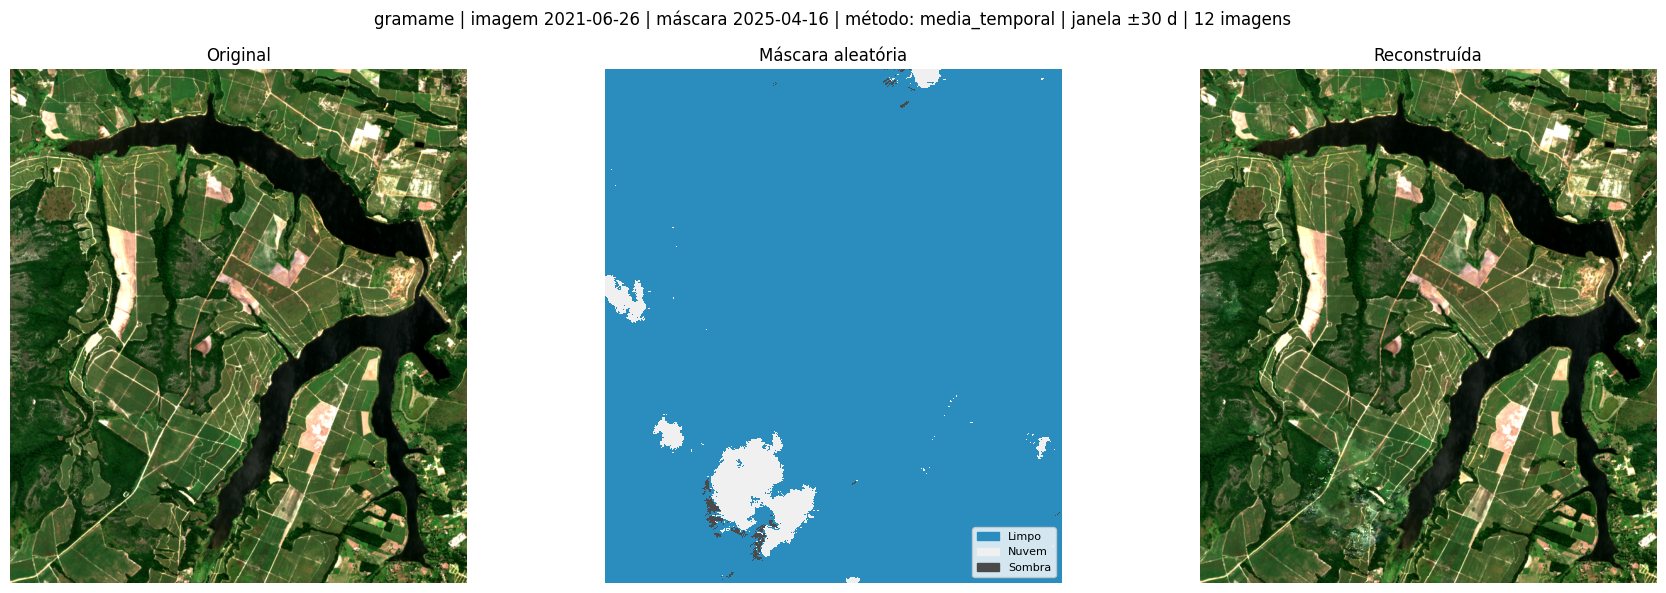

In [39]:
mostrar_resultado(
    original, mascara_cls, reconstruida,
    titulo=f"{linha['reservoir']} | imagem {linha['data']:%Y-%m-%d} | máscara {linha['data_mascara']:%Y-%m-%d} "
           f"| método: {CONFIG['metodo']} | janela ±{CONFIG['janela_dias']} d | {len(acervo)} imagens",
)

In [40]:
print(sorted(p.name for p in (DIR_MASCARAS / "gramame").iterdir()))

['s2cloudless']
